Soal 1 Membuat Database dan 3 Tabel dengan SQLite

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat koneksi ke database SQLite
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan constraint Foreign Key di SQLite
cursor.execute("PRAGMA foreign_keys = ON;")

# Reset tabel jika cell dijalankan ulang agar tidak terjadi error duplikasi
cursor.execute("DROP TABLE IF EXISTS peminjaman;")
cursor.execute("DROP TABLE IF EXISTS buku;")
cursor.execute("DROP TABLE IF EXISTS anggota;")

# 1. Tabel buku
cursor.execute("""
CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);
""")

# 2. Tabel anggota
cursor.execute("""
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE NOT NULL
);
""")

# 3. Tabel peminjaman
cursor.execute("""
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")

conn.commit()
print("Database dan ketiga tabel berhasil dibuat!")

Database dan ketiga tabel berhasil dibuat!


Soal 2 Menambahkan Data

In [2]:
# 1a. Tambah 5 data buku
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    ('Clean Code', 'Robert C. Martin', 2008),
    ('Filosofi Teras', 'Henry Manampiring', 2018),
    ('Atomic Habits', 'James Clear', 2018)
]
cursor.executemany("INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?);", data_buku)

# 1a. Tambah 3 data anggota
data_anggota = [
    ('Budi Santoso', 'budi@email.com'),
    ('Siti Aminah', 'siti@email.com'),
    ('Andi Wijaya', 'andi@email.com')
]
cursor.executemany("INSERT INTO anggota (nama, email) VALUES (?, ?);", data_anggota)

# 1b. Tambah 4 transaksi peminjaman (1 transaksi belum dikembalikan / NULL)
data_peminjaman = [
    (1, 1, '2026-10-01', '2026-10-08'),
    (1, 3, '2026-10-05', '2026-10-15'),
    (2, 2, '2026-10-10', '2026-10-14'),
    (3, 5, '2026-10-18', None)
]
cursor.executemany("""
INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?);
""", data_peminjaman)

conn.commit()
print("Data buku, anggota, dan peminjaman berhasil dimasukkan!")


Data buku, anggota, dan peminjaman berhasil dimasukkan!


Menampilkan Daftar Peminjaman

In [3]:
# 1c. Daftar peminjaman lengkap menggunakan JOIN
query_1c = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id;
"""

print("=== 1c. Daftar Peminjaman Lengkap ===")
for row in cursor.execute(query_1c):
    print(row)

# 1d. Jumlah total buku yang dipinjam per anggota menggunakan GROUP BY
query_1d = """
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama;
"""

print("\n=== 1d. Total Buku Dipinjam per Anggota ===")
for row in cursor.execute(query_1d):
    print(row)


=== 1c. Daftar Peminjaman Lengkap ===
(1, 'Budi Santoso', 'Laskar Pelangi', '2026-10-01', '2026-10-08')
(2, 'Budi Santoso', 'Clean Code', '2026-10-05', '2026-10-15')
(3, 'Siti Aminah', 'Bumi Manusia', '2026-10-10', '2026-10-14')
(4, 'Andi Wijaya', 'Atomic Habits', '2026-10-18', None)

=== 1d. Total Buku Dipinjam per Anggota ===
('Budi Santoso', 2)
('Siti Aminah', 1)
('Andi Wijaya', 1)


Membuat DataFrame & Eksplorasi Data

In [4]:
# 2a. Membuat DataFrame pandas dari hasil query 1c dan 1d
df_peminjaman = pd.read_sql_query(query_1c, conn)
df_total_pinjam = pd.read_sql_query(query_1d, conn)

print("=== DataFrame Peminjaman (1c) ===")
display(df_peminjaman)

# 2b. Eksplorasi data: konversi tanggal dan hitung durasi peminjaman (dalam hari)
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

df_peminjaman['durasi_hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days
df_peminjaman['status'] = df_peminjaman['tgl_kembali'].apply(
    lambda x: 'Belum Kembali' if pd.isna(x) else 'Sudah Kembali'
)

print("\n=== Hasil Eksplorasi Data ===")
display(df_peminjaman)

# Ringkasan statistik sederhana
rata_rata_durasi = df_peminjaman['durasi_hari'].mean()
belum_kembali = df_peminjaman['tgl_kembali'].isna().sum()

print(f"\nRata-rata durasi peminjaman (yang sudah kembali): {rata_rata_durasi:.1f} hari")
print(f"Jumlah buku yang belum dikembalikan: {belum_kembali} buku")


=== DataFrame Peminjaman (1c) ===


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Budi Santoso,Laskar Pelangi,2026-10-01,2026-10-08
1,2,Budi Santoso,Clean Code,2026-10-05,2026-10-15
2,3,Siti Aminah,Bumi Manusia,2026-10-10,2026-10-14
3,4,Andi Wijaya,Atomic Habits,2026-10-18,None



=== Hasil Eksplorasi Data ===


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari,status
0,1,Budi Santoso,Laskar Pelangi,2026-10-01,2026-10-08,7.0,Sudah Kembali
1,2,Budi Santoso,Clean Code,2026-10-05,2026-10-15,10.0,Sudah Kembali
2,3,Siti Aminah,Bumi Manusia,2026-10-10,2026-10-14,4.0,Sudah Kembali
3,4,Andi Wijaya,Atomic Habits,2026-10-18,NaT,NaN,Belum Kembali



Rata-rata durasi peminjaman (yang sudah kembali): 7.0 hari
Jumlah buku yang belum dikembalikan: 1 buku


Visualisasi Data

/tmp/ipykernel_643/4207544413.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


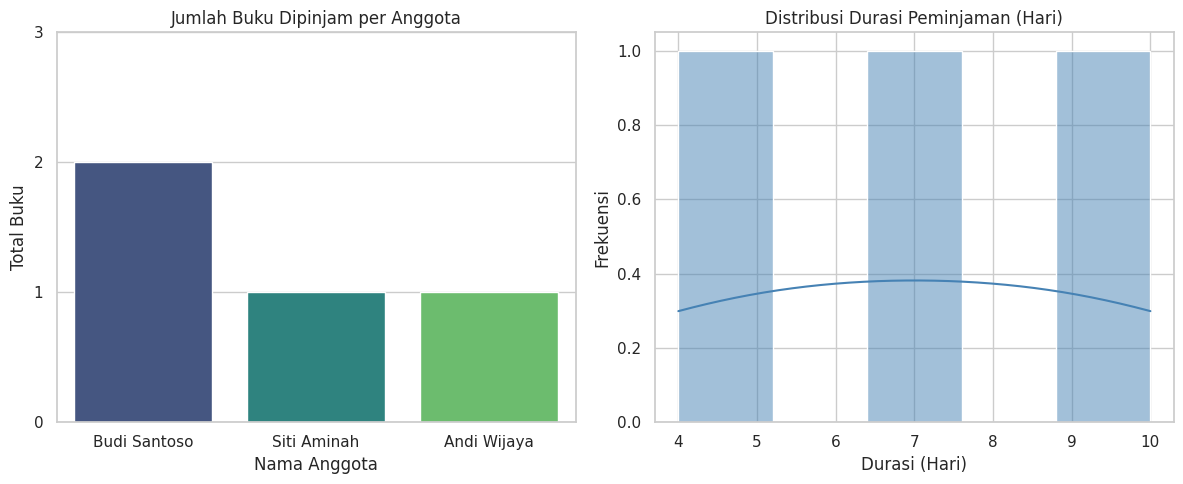

In [5]:
# 2c. Visualisasi distribusi data menggunakan Matplotlib & Seaborn
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafik 1: Diagram Batang Jumlah Buku Dipinjam per Anggota
sns.barplot(
    data=df_total_pinjam,
    x='nama_anggota',
    y='total_buku_dipinjam',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Jumlah Buku Dipinjam per Anggota')
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Total Buku')
axes[0].set_yticks(range(0, df_total_pinjam['total_buku_dipinjam'].max() + 2))

# Grafik 2: Histogram Distribusi Durasi Peminjaman (mengabaikan nilai NULL/NaN)
sns.histplot(
    data=df_peminjaman.dropna(subset=['durasi_hari']),
    x='durasi_hari',
    bins=5,
    kde=True,
    color='steelblue',
    ax=axes[1]
)
axes[1].set_title('Distribusi Durasi Peminjaman (Hari)')
axes[1].set_xlabel('Durasi (Hari)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

# Tutup koneksi database setelah selesai
conn.close()
